Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.
Perform following tasks:
1.  Pre-process the dataset.
2.  Identify outliers.
3.  Check the correlation.
4.  Implement linear regression and random forest regression models.
5.  Evaluate the models and compare their respective scores like R2, RMSE, etc.
Dataset link: https://www.kaggle.com/datasets/yasserh/uber-fares-dataset

In [101]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [102]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error , r2_score , mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

In [103]:
df = pd.read_csv("uber.csv")
df

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1


In [104]:
df.columns

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')

In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [106]:
df.shape

(200000, 9)

In [107]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [108]:
df.isnull().sum()

,0
Unnamed: 0,0
key,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,1
dropoff_latitude,1
passenger_count,0


In [109]:
df = df.dropna()
df.isnull().sum()

,0
Unnamed: 0,0
key,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
passenger_count,0


In [110]:
print("Number of zero fares:" , (df['fare_amount']<=0).sum())

Number of zero fares: 22


In [111]:
print("Invalid Passenger Count:" , (df['passenger_count']<=0).sum())

Invalid Passenger Count: 708


In [112]:
print("Maximum passenger count" , (df['passenger_count'].max()))

Maximum passenger count 208


In [113]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,1.999990e+05,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000
mean,2.771248e+07,11.359892,-72.527631,39.935881,-72.525292,39.923890,1.684543
std,1.601386e+07,9.901760,11.437815,7.720558,13.117408,6.794829,1.385995
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382534e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774524e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155535e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [114]:
df.columns

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')

In [115]:
df = df.drop(["Unnamed: 0" , "key" , "pickup_datetime"] , axis = 1)

In [116]:
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5
...,...,...,...,...,...,...
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1
199996,7.5,-73.984722,40.736837,-74.006672,40.739620,1
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1


In [117]:
df = df[
    (df["passenger_count"] >= 1) &
    (df['fare_amount'] > 0) &
    (df['passenger_count'] < 6) &
    (df['pickup_longitude'].between(-74 , -72)) &
    (df['dropoff_longitude'].between(-74 , -72)) &
    (df['pickup_latitude'].between(40 , 42)) &
    (df['dropoff_latitude'].between(40 , 42))

]


In [118]:
df

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5
5,4.9,-73.969019,40.755910,-73.969019,40.755910,1
...,...,...,...,...,...,...
199994,12.0,-73.983070,40.760770,-73.972972,40.754177,1
199995,3.0,-73.987042,40.739367,-73.986525,40.740297,1
199997,30.9,-73.986017,40.756487,-73.858957,40.692588,2
199998,14.5,-73.997124,40.725452,-73.983215,40.695415,1


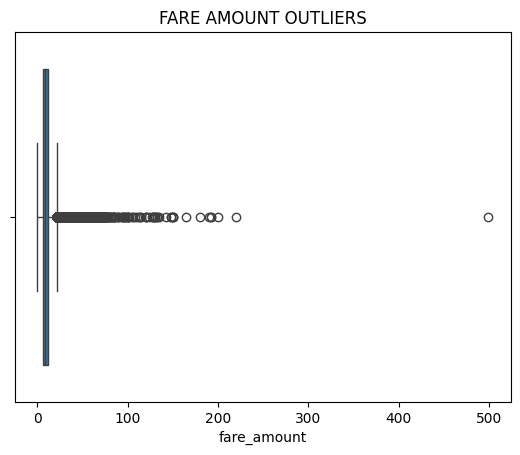

In [119]:
sns.boxplot(x = df['fare_amount'])
plt.title("FARE AMOUNT OUTLIERS")
plt.show()

In [120]:
Q1  = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR



In [121]:
df = df[((df['fare_amount'] >= lower) & (df['fare_amount'] <= upper))]

In [122]:
df.shape

(133235, 6)

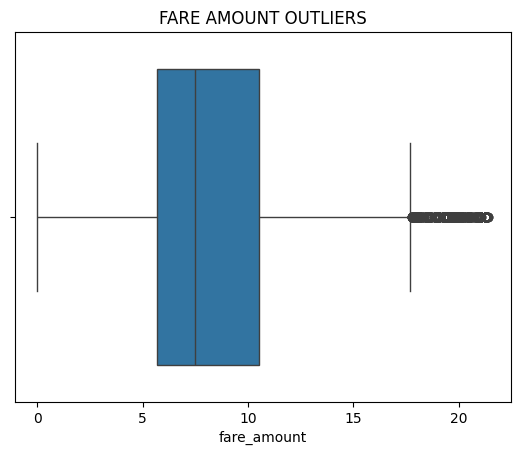

In [123]:
sns.boxplot(x = df['fare_amount'])
plt.title("FARE AMOUNT OUTLIERS")
plt.show()

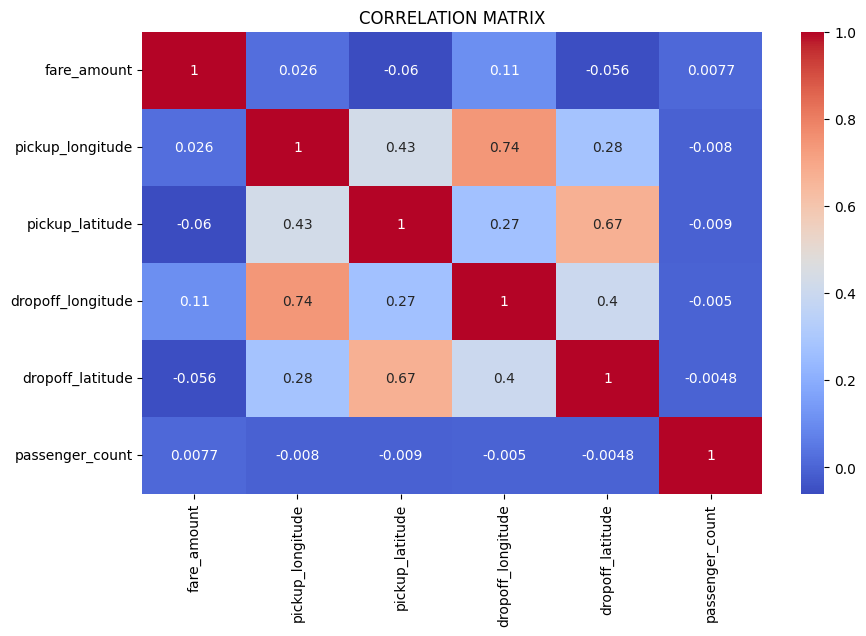

In [124]:
plt.figure(figsize = (10 , 6))

sns.heatmap(df.corr() , annot = True ,  cmap = 'coolwarm')

plt.title("CORRELATION MATRIX")
plt.show()


In [125]:
X = df.drop('fare_amount' , axis = 1)
y = df['fare_amount']

In [126]:
X_train ,  X_test ,y_train , y_test = train_test_split(X , y , random_state = 42 , test_size = 0.2)

In [127]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(106588, 5)
(106588,)
(26647, 5)
(26647,)


In [128]:
model = LinearRegression()
model.fit(X_train , y_train)

LinearRegression()

In [129]:
y_pred = model.predict(X_test)
y_pred

array([8.36119851, 8.45667495, 8.74392214, ..., 8.9321981 , 8.5340285 ,
       8.89180102])

In [130]:
r2 = r2_score(y_test , y_pred)
mae = mean_absolute_error(y_test , y_pred)
mse = mean_squared_error(y_test , y_pred)
rmse = np.sqrt(mse)

In [131]:
print("R2 Score:", r2)
print("RMSE:", rmse)
print("MAE:", mae)

R2 Score: 0.037108185689901485
RMSE: 3.8088674373147287
MAE: 3.012461670585745


In [132]:
result = pd.DataFrame({'Actual': y_test , 'Predicted': y_pred})
result

,Actual,Predicted
158427,4.5,8.361199
127298,2.5,8.456675
159014,6.0,8.743922
50786,4.5,8.566483
30471,10.5,8.336905
...,...,...
58892,19.0,10.171809
468,4.9,8.035880
1040,9.0,8.932198
133891,5.0,8.534028


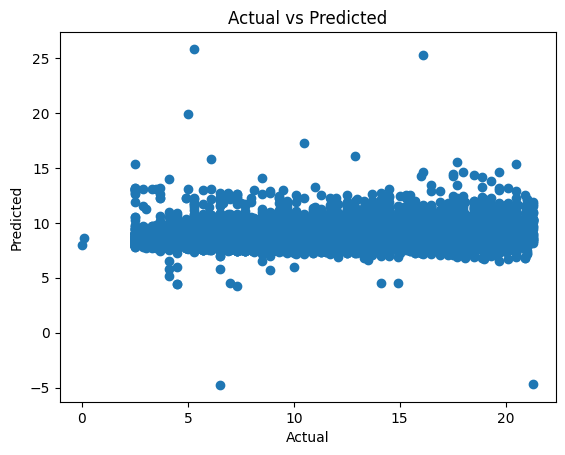

In [133]:
plt.scatter(y_test , y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

In [134]:
rf = RandomForestRegressor(n_estimators=100 , random_state = 42)
rf.fit(X_train , y_train)

RandomForestRegressor(random_state=42)

In [135]:
y_predrf = rf.predict(X_test)
y_predrf

array([4.984, 5.213, 5.235, ..., 9.221, 4.585, 7.48 ])

In [141]:
r2_rf = r2_score(y_test, y_predrf)

mae_rf = mean_absolute_error(y_test, y_predrf)

mse_rf = mean_squared_error(y_test, y_predrf)

rmse_rf = np.sqrt(mse_rf)

print("R2 Score:", r2_rf)
print("RMSE:", rmse_rf)
print("MAE:", mae_rf)

R2 Score: 0.7065074542256261
RMSE: 2.102837185180084
MAE: 1.4883123449828632


In [142]:
result_rf = pd.DataFrame({'Actual': y_test , 'Predicted': y_predrf})
result_rf

,Actual,Predicted
158427,4.5,4.984
127298,2.5,5.213
159014,6.0,5.235
50786,4.5,5.434
30471,10.5,10.908
...,...,...
58892,19.0,14.857
468,4.9,4.925
1040,9.0,9.221
133891,5.0,4.585


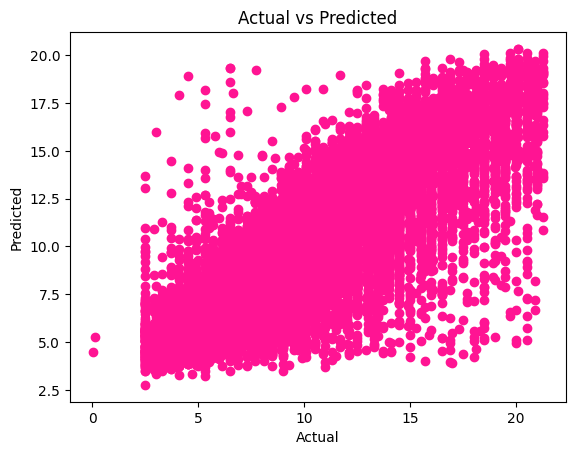

In [143]:
plt.scatter(y_test , y_predrf , color = 'deeppink')
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted")
plt.show()

In [144]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'R2 Score': [r2, r2_rf],
    'RMSE': [rmse, rmse_rf],
    'MAE': [mae, mae_rf]
})

print(comparison)

               Model  R2 Score      RMSE       MAE
0  Linear Regression  0.037108  3.808867  3.012462
1      Random Forest  0.706507  2.102837  1.488312


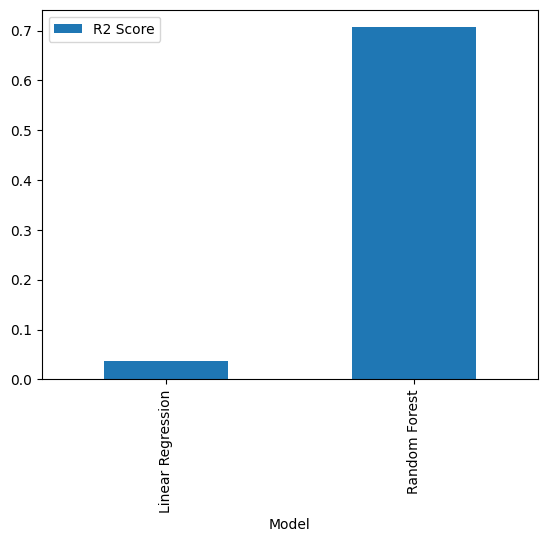

In [145]:
comparison.plot(x = "Model" , y = "R2 Score" , kind = "bar")
plt.show()

## CONCLUSION

Random Forest Regression performs better than Linear Regression for Uber fare prediction.

Linear Regression gives an R² score of 0.0371, whereas Random Forest gives an R² score of 0.7065. Random Forest also has lower RMSE and MAE values.

Therefore, Random Forest Regression is the better-performing model for predicting Uber ride fares on this dataset.

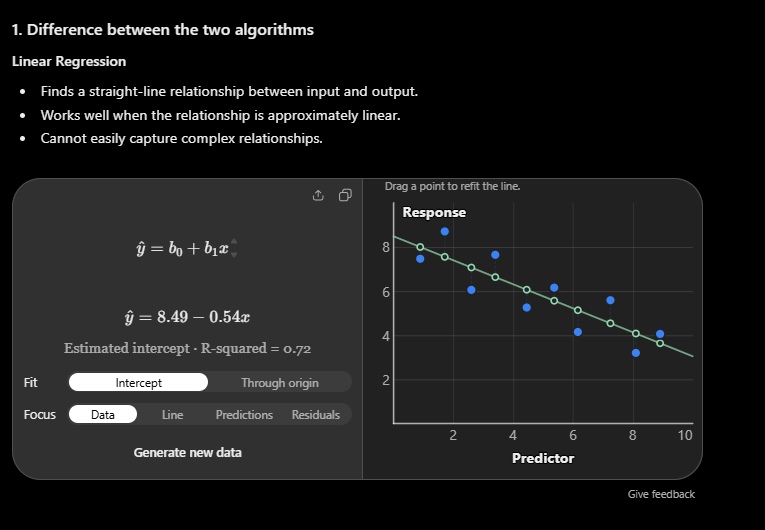

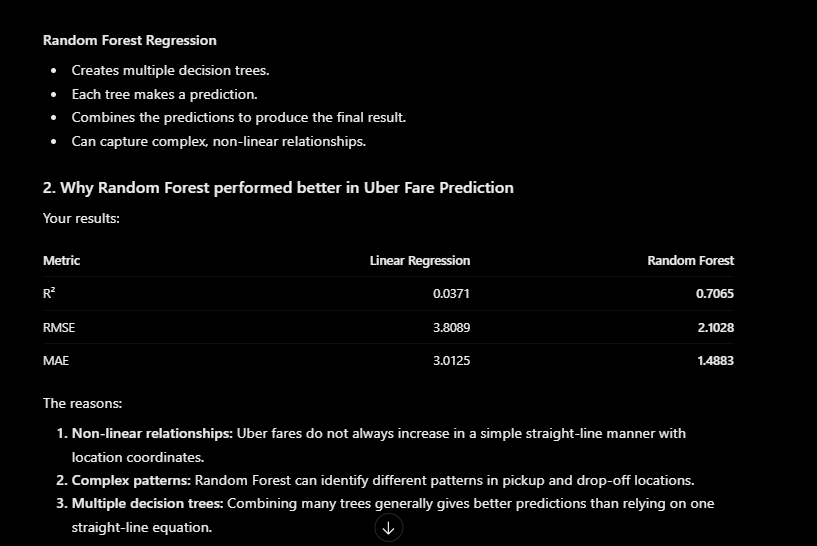